**과제 (강의자료 Ch3 p47, Homework)**
- Read chapters 2 and 3
- Solve the exercises covered during the classes 
- Solve Exercise 3.24

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
os.makedirs('figures', exist_ok=True)

**Exercise 3.1: MDP로 표현 가능한 과제 3개**

MDP는 (상태 $S$, 행동 $A$, 보상 $R$, 전이 확률 $p(s',r|s,a)$)로 정의되고, 다음 상태와 보상이 현재 상태와 행동에만 의존해야 한다.

1. 공부 계획 도우미 ; (상태)과목별 이해도/남은 시간, (보상)시험 점수, (행동)다음에 공부할 과목 
2. 로봇 청소기 ; (상태)배터리,위치, 청소한 장소 , (행동)움직일 위치 선정/충전, (보상) 청소한칸+, 방전-
3. 편의점 재고 관리; (상태)남은 재고/다음 입고까지의 시간, (보상)수익, (행동)채울 재고 수량

--------------------------

**Exercise 3.2: MDP로 표현이 어려운 과제**

1. 다음 상태와 보상이 현재 상태와 행동에만 의존하지 않는 경우
2. 단순 숫자로 표현하기 어려운 보상이 존재하는 경우
3. 목표가 도중에 바뀌는 경우

---

**Exercise 3.5: 식 3.3의 에피소딕 버전**

기존 식:

$$\sum_{s'\in\mathcal S}\sum_{r\in\mathcal R}p(s',r\mid s,a)=1,\quad \text{for all } s\in\mathcal S,\ a\in\mathcal A(s)$$

에피소드 버전: 에피소딕 과제에서는 다음 상태가 종료 상태(terminal state)일 수도 있어서 다음 상태 $s'$의 범위를 종료 이전 상태 집합 $\mathcal S$에서 종료 상태까지 포함한 집합으로 바꾼다.

---

**Exercise 3.6** :  Suppose you treated pole-balancing as an episodic task but also used discounting, with all rewards zero except for −1 upon failure. What then would the return be at each time? How does this return differ from that in the discounted, continuing formulation of this task?

에피소딕은 다음 한 번의 실패만 반영하고 연속은 모든 실패를 할인해서 더한다; 그래서 연속 버전의 리턴이 더 작다. 다만 다음 실패를 늦출수록 리턴이 커진다는 점은 같아서, 둘 다 가능한 오래 버티는 방식을 학습한다.

---

**Exercise 3.7** :  Imagine that you are designing a robot to run a maze....... What is going wrong? Have you effectively communicated to the agent what you want it to achieve?

3.7의 문제는 미로를 탈출 하기만 하면 몇 트라이든 전부 보상이 동일한게 문제다(You decide to give it a reward of +1 for escaping from the maze and a reward of zero at all other times). 결과적으로 어느게 최적의 정책인지 구분할 수가 없기 때문에 당연히 improvement가 발생하지 않는다. agent 와 제대로 된 소통이 되지 않은 예시이다.

---

**Exercise 3.8**: Suppose $\gamma=0.5$ and the following sequence of rewards is received $R_1=-1$, $R_2=2$, $R_3=6$, $R_4=3$, and $R_5=2$, with $T=5$. What are $G_0, G_1, \ldots, G_5$? Hint: Work backwards.

- $G_5=0$
- $R_5+\gamma G_5=2+0.5\cdot0$ |   $G_4$ = 2
- $R_4+\gamma G_4=3+0.5\cdot2$ |   $G_3$ = 4
- $R_3+\gamma G_3=6+0.5\cdot4$ |   $G_2$ = 8
- $R_2+\gamma G_2=2+0.5\cdot8$ |   $G_1$ = 6
- $R_1+\gamma G_1=-1+0.5\cdot6$ |   $G_0$ = 2

즉 $G_5$ = 0, $G_4$ = 2, $G_3$ = 4, $G_2$ = 8, $G_1$ = 6, $G_0$ = 2

---

**Exercise 3.9**: Suppose $\gamma=0.9$ and the reward sequence is $R_1=2$ followed by an infinite sequence of 7s. What are $G_1$ and $G_0$?

$$G_1=7+0.9\cdot7+0.9^2\cdot7+\cdots=7\sum_{k=0}^{\infty}0.9^k=\frac{7}{1-0.9}=\mathbf{70}$$
$$G_0=R_1+\gamma G_1=2+0.9\cdot70=\mathbf{65}$$

---

**Exercise 3.10**: Prove the second equality in (3.10): $\displaystyle G_t=\sum_{k=0}^{\infty}\gamma^k=\frac{1}{1-\gamma}$ (보상이 항상 +1, $0\le\gamma<1$)

$$S_n=1+\gamma+\gamma^2+\cdots+\gamma^n$$
$$\gamma S_n=\gamma+\gamma^2+\cdots+\gamma^{n+1}$$
$$S_n-\gamma S_n=1-\gamma^{n+1}\quad\Rightarrow\quad S_n=\frac{1-\gamma^{n+1}}{1-\gamma}$$
$$\sum_{k=0}^{\infty}\gamma^k=\lim_{n\to\infty}S_n=\frac{1}{1-\gamma}$$

따라서 $\gamma<1$ 이 필요하다; $\gamma=1$이면 합이 무한대가 되기 때문.

---

**GridWorld**

교재 Example 3.5 (Figure 3.2)

- 5×5, 행동 4개 (방향), $\gamma=0.9$
- A에서는 어떤 행동이든 +10을 받고 A′로, B에서는 +5를 받고 B′로 이동
- 격자 밖으로 나가려 하면 −1을 받고 제자리, 나머지는 보상 0

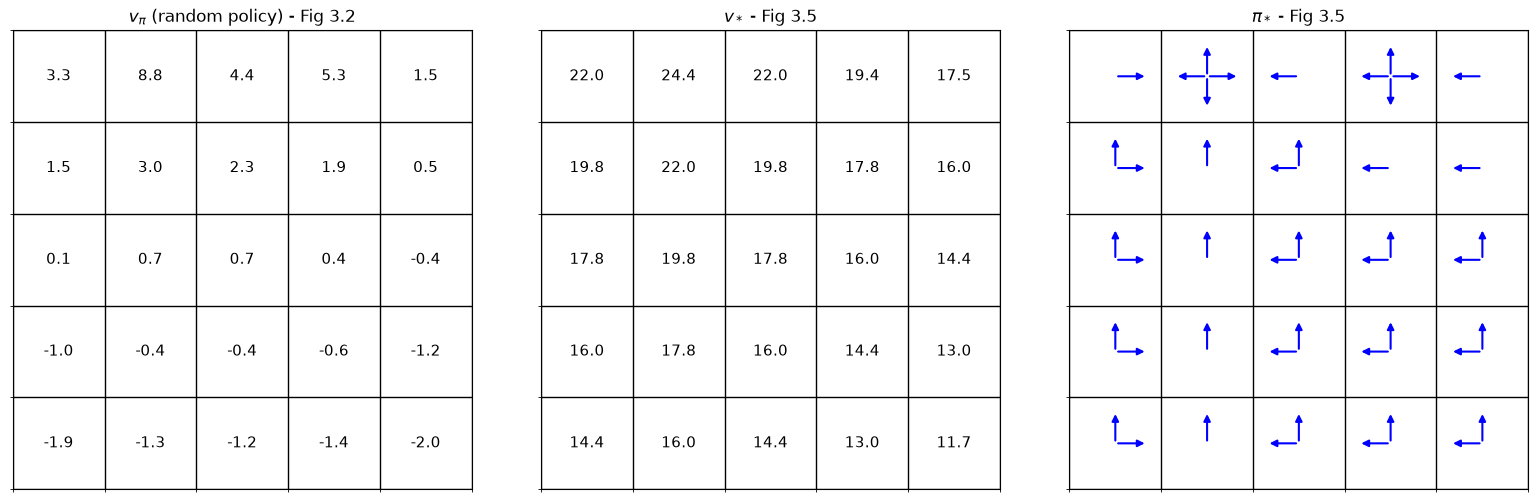

In [3]:
WORLD_SIZE = 5
A_POS, A_PRIME_POS = (0, 1), (4, 1)
B_POS, B_PRIME_POS = (0, 3), (2, 3)
GAMMA = 0.9
ACTIONS = [(-1, 0), (1, 0), (0, -1), (0, 1)]     # North, South, West, East
ACTION_PROB = 0.25                               # 균등 무작위 정책

def step(state, action):
    if state == A_POS:
        return A_PRIME_POS, 10.0
    if state == B_POS:
        return B_PRIME_POS, 5.0
    r, c = state[0] + action[0], state[1] + action[1]
    if r < 0 or r >= WORLD_SIZE or c < 0 or c >= WORLD_SIZE:
        return state, -1.0
    return (r, c), 0.0

def evaluate_random_policy(theta=1e-12):
    # 벨만 기대 방정식 반복: v(s) <- sum_a pi(a|s) [r + gamma v(s')]
    V = np.zeros((WORLD_SIZE, WORLD_SIZE))
    while True:
        new_V = np.zeros_like(V)
        for i in range(WORLD_SIZE):
            for j in range(WORLD_SIZE):
                for a in ACTIONS:
                    (ni, nj), r = step((i, j), a)
                    new_V[i, j] += ACTION_PROB * (r + GAMMA * V[ni, nj])
        if np.max(np.abs(new_V - V)) < theta:
            return new_V
        V = new_V

def optimal_values(theta=1e-12):
    # 벨만 최적 방정식 반복 (value iteration): v(s) <- max_a [r + gamma v(s')]
    V = np.zeros((WORLD_SIZE, WORLD_SIZE))
    while True:
        new_V = np.zeros_like(V)
        for i in range(WORLD_SIZE):
            for j in range(WORLD_SIZE):
                new_V[i, j] = max(r + GAMMA * V[s2] for s2, r in (step((i, j), a) for a in ACTIONS))
        if np.max(np.abs(new_V - V)) < theta:
            return new_V
        V = new_V

def optimal_policy(V, tol=1e-6):
    pi = {}
    for i in range(WORLD_SIZE):
        for j in range(WORLD_SIZE):
            q = [r + GAMMA * V[s2] for s2, r in (step((i, j), a) for a in ACTIONS)]
            pi[(i, j)] = [ACTIONS[k] for k, v in enumerate(q) if abs(v - max(q)) < tol]
    return pi

def draw_values(ax, V, title, fmt='{:.1f}'):
    ax.imshow(np.zeros_like(V), cmap='Greys', vmin=0, vmax=1)
    for i in range(WORLD_SIZE):
        for j in range(WORLD_SIZE):
            ax.text(j, i, fmt.format(V[i, j]), ha='center', va='center', fontsize=11)
    ax.set_xticks(np.arange(-.5, WORLD_SIZE), minor=True)
    ax.set_yticks(np.arange(-.5, WORLD_SIZE), minor=True)
    ax.grid(which='minor', color='k', lw=1)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_title(title)

V_pi = evaluate_random_policy()
V_star = optimal_values()
pi_star = optimal_policy(V_star)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
draw_values(axes[0], V_pi, r'$v_\pi$ (random policy) - Fig 3.2')
draw_values(axes[1], V_star, r'$v_*$ - Fig 3.5')
draw_values(axes[2], np.zeros_like(V_star), r'$\pi_*$ - Fig 3.5', fmt='')
for (i, j), acts in pi_star.items():
    for di, dj in acts:
        axes[2].annotate('', xy=(j + 0.35 * dj, i + 0.35 * di), xytext=(j, i),
                         arrowprops=dict(arrowstyle='-|>', color='blue', lw=1.5))
plt.tight_layout(); plt.savefig('figures/gridworld_values.png', dpi=150); plt.show()

**Exercise 3.14**

$$v_\pi(\text{center})=\tfrac14\big[0+0.9(2.3)\big]+\tfrac14\big[0+0.9(0.4)\big]+\tfrac14\big[0+0.9(-0.4)\big]+\tfrac14\big[0+0.9(0.7)\big]$$
$$=\tfrac{0.9}{4}(2.3+0.4-0.4+0.7)=0.225\times3.0=\mathbf{0.675}\approx0.7$$

---

**Exercise 3.18**

$$v_\pi(s)=\mathbb E_\pi[q_\pi(S_t,A_t)\mid S_t=s]=\sum_a\pi(a|s)q_\pi(s,a)$$

---

**Exercise 3.19**

$$q_\pi(s,a)=\mathbb E\big[R_{t+1}+\gamma\,v_\pi(S_{t+1})\,\big|\,S_t=s,\,A_t=a\big]$$
$$q_\pi(s,a)=\sum_{s',r}p(s',r\mid s,a)\big[r+\gamma\,v_\pi(s')\big]$$

---

**Exercise 3.22**

- **left**: 보상 $+1, 0, +1, 0, \ldots$ → $v_{left}=1+\gamma^2+\gamma^4+\cdots=\dfrac{1}{1-\gamma^2}$
- **right**: 보상 $0, +2, 0, +2, \ldots$ → $v_{right}=2\gamma+2\gamma^3+\cdots=\dfrac{2\gamma}{1-\gamma^2}$

- 0 ; 1 / 0 ; left
- 0.9 ; 5.263 / 9.474 ; right
- 0.5 ; 1.333 / 1.333 ; both

---

**Exercise 3.24**

$$v_*(A)=10+\gamma^5\cdot10+\gamma^{10}\cdot10+\cdots=10\sum_{k=0}^{\infty}(\gamma^5)^k=\frac{10}{1-\gamma^5}$$
$\gamma=0.9$이면 $\gamma^5=0.59049$이므로
$$v_*(A)=\frac{10}{1-0.59049}=\frac{10}{0.40951}\approx\mathbf{24.419}$$

---